In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
fake_news = pd.read_csv("../dataset/Fake.csv")
real_news = pd.read_csv("../dataset/True.csv")

print("Fake News Shape:", fake_news.shape)
print("Real News Shape:", real_news.shape)

# print("FAKE NEWS DATA")
# display(fake_news.head())
# print("REAL NEWS DATA")
# display(real_news.head())

fake_news["label"] = 0
real_news["label"] = 1

display(fake_news.head())
display(real_news.head())

Fake News Shape: (23481, 4)
Real News Shape: (21417, 4)


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1


In [3]:
# combining both datasets and shuffling
df = pd.concat([fake_news, real_news], axis=0)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Combined Dataset Shape:", df.shape)
display(df.head())

Combined Dataset Shape: (44898, 5)


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [4]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nLabel Distribution:")
print(df["label"].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    44898 non-null  str  
 1   text     44898 non-null  str  
 2   subject  44898 non-null  str  
 3   date     44898 non-null  str  
 4   label    44898 non-null  int64
dtypes: int64(1), str(4)
memory usage: 112.3 MB

Missing Values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Duplicate Rows:
209

Label Distribution:
label
0    23481
1    21417
Name: count, dtype: int64


In [5]:
# removing duplicate articles
print("Before removing duplicates:", df.shape)
df = df.drop_duplicates()
print("After removing duplicates:", df.shape)

# removing unnecessary columns 
df = df.drop(["date", "subject"], axis=1)
display(df.head())

Before removing duplicates: (44898, 5)


After removing duplicates: (44689, 5)


,title,text,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",1


In [6]:
# combining title and text as content
df["content"] = df["title"] + " " + df["text"]
df = df[["content", "label"]]
display(df.head())

,content,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,0
1,Trump drops Steve Bannon from National Securit...,1
2,Puerto Rico expects U.S. to lift Jones Act shi...,1
3,OOPS: Trump Just Accidentally Confirmed He Le...,0
4,Donald Trump heads for Scotland to reopen a go...,1


In [7]:
# removing URLs, punctuation and special characters
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["content"] = df["content"].apply(clean_text)
display(df.head())

,content,label
0,ben stein calls out th circuit court committed...,0
1,trump drops steve bannon from national securit...,1
2,puerto rico expects u s to lift jones act ship...,1
3,oops trump just accidentally confirmed he leak...,0
4,donald trump heads for scotland to reopen a go...,1


In [8]:
# removing stop words like "the, is, am, are, and, of"
import nltk

nltk.download("stopwords")
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

def remove_stopwords(text):
    words = text.split()
    filtered_words = [
        word for word in words
        if word not in stop_words
    ]
    return " ".join(filtered_words)

df["content"] = df["content"].apply(remove_stopwords)
remaining_after_removal = set(" ".join(df["content"]).split()).intersection(stop_words)

print("Stopwords remaining BEFORE stemming:", len(remaining_after_removal))
print("Words:", sorted(remaining_after_removal))

display(df.head())

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Stopwords remaining BEFORE stemming: 0
Words: []


,content,label
0,ben stein calls th circuit court committed cou...,0
1,trump drops steve bannon national security cou...,1
2,puerto rico expects u lift jones act shipping ...,1
3,oops trump accidentally confirmed leaked israe...,0
4,donald trump heads scotland reopen golf resort...,1


In [9]:
# applying stemming (converts words into their root-like forms, Playing -> Play, Connected -> Connect)
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

def apply_stemming(text):
    words = text.split()
    stemmed_words = [
        stemmer.stem(word) for word in words
    ]
    return " ".join(stemmed_words)

df["content"] = df["content"].apply(apply_stemming)

remaining_after_stemming = set(" ".join(df["content"]).split()).intersection(stop_words)

print("Stopwords remaining AFTER stemming:", len(remaining_after_stemming))
print("Words:", sorted(remaining_after_stemming))

display(df.head())

Stopwords remaining AFTER stemming: 62
Words: ['again', 'ain', 'all', 'an', 'and', 'are', 'as', 'be', 'been', 'but', 'by', 'can', 'do', 'don', 'down', 'few', 'for', 'further', 'have', 'haven', 'he', 'her', 'here', 'how', 'i', 'if', 'in', 'just', 'll', 'ma', 'more', 'no', 'not', 'of', 'off', 'on', 'other', 'out', 'over', 'own', 're', 'same', 'she', 'so', 'than', 'that', 'there', 'these', 'through', 'to', 'too', 'until', 'up', 'we', 'were', 'what', 'where', 'while', 'will', 'with', 'you', 'your']


,content,label
0,ben stein call th circuit court commit coup ta...,0
1,trump drop steve bannon nation secur council w...,1
2,puerto rico expect u lift jone act ship restri...,1
3,oop trump accident confirm leak isra intellig ...,0
4,donald trump head scotland reopen golf resort ...,1


In [10]:
print("Dataset shape:", df.shape)

print("\nFirst cleaned article:")
print(df["content"].iloc[0])

print("\nMissing values:")
print(df.isnull().sum())  

Dataset shape: (44689, 2)

First cleaned article:
ben stein call th circuit court commit coup tat constitut st centuri wire say ben stein reput professor pepperdin univers also hollywood fame appear tv show film ferri bueller day made provoc statement judg jeanin pirro show recent discuss halt impos presid trump execut order travel stein refer judgement th circuit court washington state coup tat execut branch constitut stein went call judg seattl polit puppet judiciari polit pawn watch interview complet statement note stark contrast rhetor leftist media pundit neglect note court ever block presidenti order immigr past discuss legal efficaci halt actual text execut order read trump news st centuri wire trump filessupport work subscrib becom member wire tv

Missing values:
content    0
label      0
dtype: int64


In [11]:

# ==========================================
# FINAL DATASET QUALITY CHECK
# ==========================================

# Fill missing content
df["content"] = df["content"].fillna("")

# Remove genuinely empty articles
df = df[df["content"].str.strip() != ""].copy()
df.reset_index(drop=True, inplace=True)

# Dataset quality checks
missing_values = df.isnull().sum().sum()
duplicate_rows = df.duplicated().sum()
empty_articles = (df["content"].str.strip() == "").sum()

print("========== DATASET QUALITY REPORT ==========")
print("Final Dataset Shape:", df.shape)
print("Stopwords before stemming:", len(remaining_after_removal))
print("Missing Values:", missing_values)
print("Duplicate Content + Label Rows:", duplicate_rows)
print("Empty Articles:", empty_articles)
print("============================================")

# Validate
assert len(remaining_after_removal) == 0, "Stopword removal failed!"
assert missing_values == 0, "Missing values found!"
assert empty_articles == 0, "Empty articles found!"

print("\nSUCCESS: All quality checks passed!")

# Save final cleaned dataset
df.to_csv("../dataset/cleaned_news.csv", index=False)

print("Cleaned dataset saved successfully!")


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_35524\2979923526.py:10: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.reset_index(drop=True, inplace=True)


========== DATASET QUALITY REPORT ==========
Final Dataset Shape: (44680, 2)
Stopwords before stemming: 0
Missing Values: 0
Duplicate Content + Label Rows: 5854
Empty Articles: 0

SUCCESS: All quality checks passed!
Cleaned dataset saved successfully!


In [12]:
df.to_csv("../dataset/cleaned_news.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


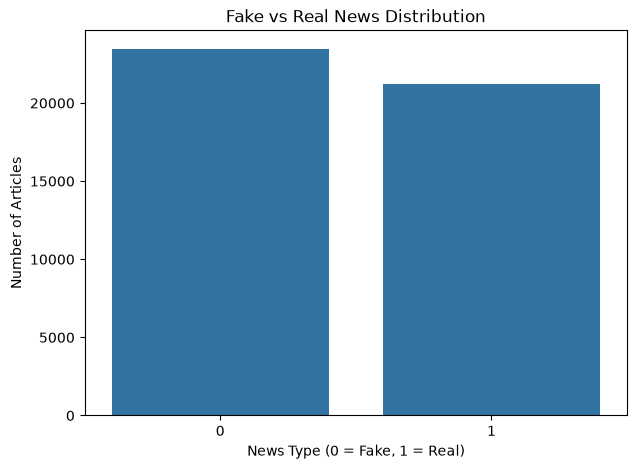

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="label")

plt.title("Fake vs Real News Distribution")
plt.xlabel("News Type (0 = Fake, 1 = Real)")
plt.ylabel("Number of Articles")

plt.show()

In [14]:

label_counts = df["label"].value_counts()

percentages = (label_counts / len(df) * 100)

print("News Distribution (%):")
print(percentages)

News Distribution (%):
label
0    52.526858
1    47.473142
Name: count, dtype: float64


In [15]:
# finding out the most common words in fake news
from collections import Counter

fake_text = " ".join(df[df["label"] == 0]["content"])
fake_words = Counter(fake_text.split())

print("Top 20 Words in Fake News:")
print(fake_words.most_common(20))

Top 20 Words in Fake News:
[('trump', 89467), ('said', 33956), ('presid', 31663), ('peopl', 27195), ('one', 26083), ('state', 26058), ('would', 23826), ('like', 22408), ('say', 21874), ('obama', 21658), ('clinton', 21034), ('time', 19978), ('year', 19539), ('american', 18911), ('donald', 18638), ('video', 17685), ('republican', 17630), ('go', 17299), ('hillari', 16505), ('report', 16488)]


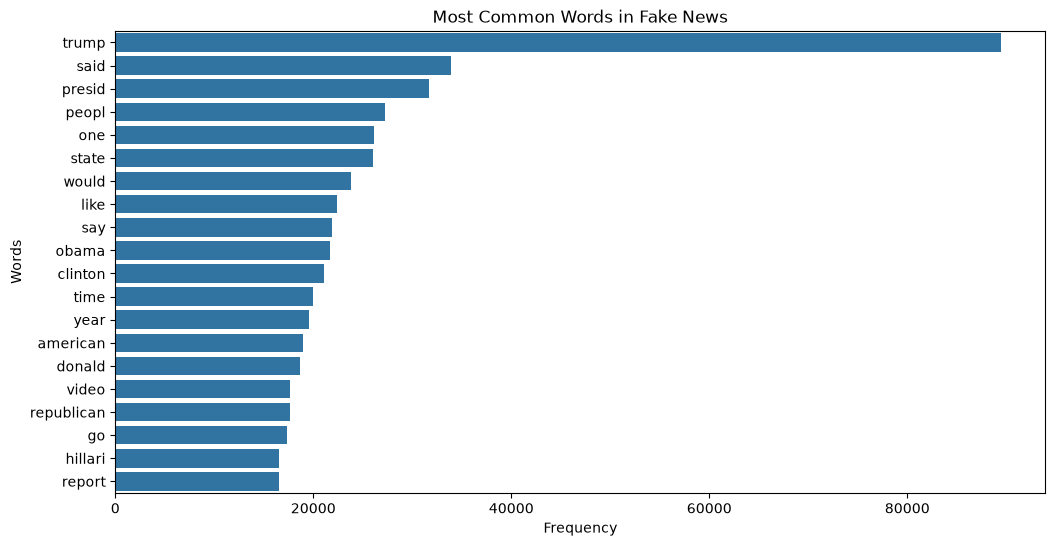

In [16]:
fake_common = fake_words.most_common(20)

words = [word for word, count in fake_common]
counts = [count for word, count in fake_common]
plt.figure(figsize=(12, 6))
sns.barplot(x=counts, y=words)

plt.title("Most Common Words in Fake News")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.show()

In [17]:
# finding out the most common words in real news
real_text = " ".join(df[df["label"] == 1]["content"])
real_words = Counter(real_text.split())

print("Top 20 Words in Real News:")
print(real_words.most_common(20))

Top 20 Words in Real News:
[('said', 97881), ('trump', 59679), ('u', 48719), ('state', 38299), ('would', 31480), ('presid', 30426), ('reuter', 28808), ('republican', 23843), ('year', 22607), ('govern', 20890), ('hous', 18938), ('say', 18882), ('elect', 18460), ('new', 17630), ('democrat', 16874), ('senat', 16821), ('unit', 16398), ('also', 15765), ('parti', 15530), ('peopl', 15263)]


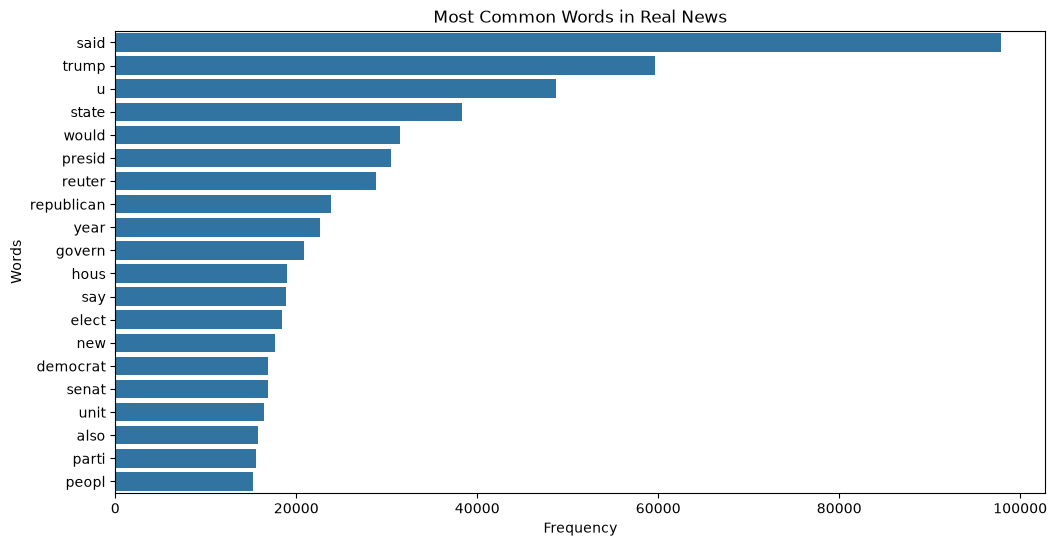

In [18]:
real_common = real_words.most_common(20)

words = [word for word, count in real_common]
counts = [count for word, count in real_common]
plt.figure(figsize=(12, 6))
sns.barplot(x=counts, y=words)

plt.title("Most Common Words in Real News")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.show()

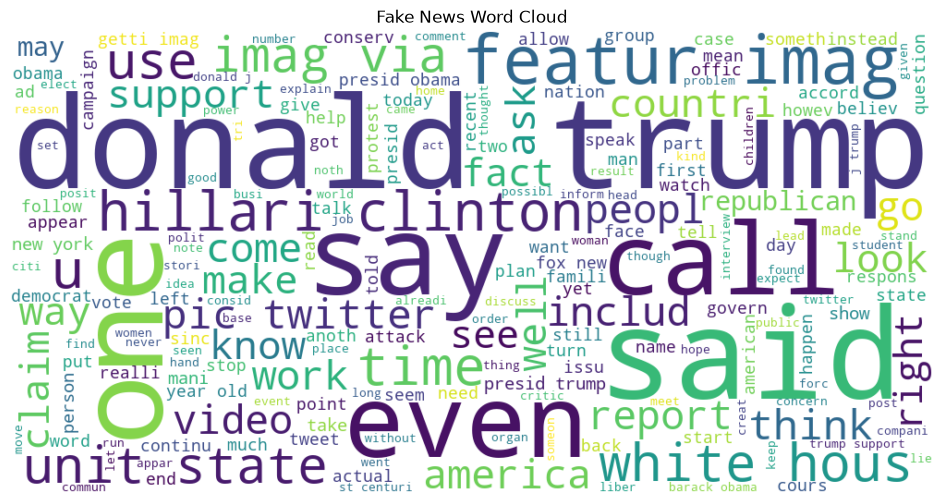

In [19]:
from wordcloud import WordCloud

fake_wc = WordCloud(width=1000, height=500, background_color="white").generate(fake_text)

plt.figure(figsize=(12, 6))
plt.imshow(fake_wc, interpolation="bilinear")
plt.axis("off")
plt.title("Fake News Word Cloud")
plt.show()

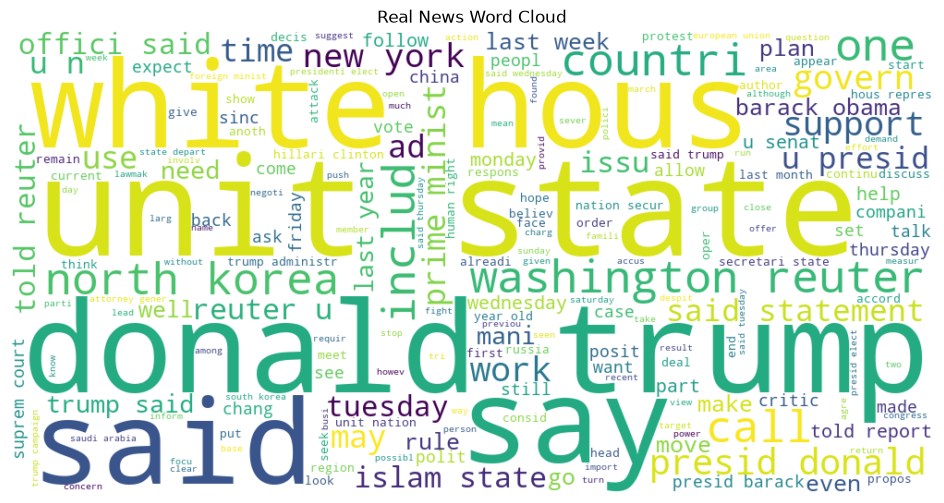

In [20]:
real_wc = WordCloud(width=1000, height=500, background_color="white").generate(real_text)

plt.figure(figsize=(12, 6))
plt.imshow(real_wc, interpolation="bilinear")
plt.axis("off")
plt.title("Real News Word Cloud")
plt.show()

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# separating input and output
X = df["content"]
y = df["label"]
print("Input shape:", X.shape)
print("Output shape:", y.shape)

# splitting the datsset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Input shape: (44680,)
Output shape: (44680,)


Training data: (35744,)
Testing data: (8936,)
Training labels: (35744,)
Testing labels: (8936,)


In [22]:
tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=2, max_df=0.95)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (35744, 10000)
Testing TF-IDF Shape: (8936, 10000)


In [23]:
print(X_train_tfidf[0])

feature_names = tfidf.get_feature_names_out()
print("First 30 Features:")
print(feature_names[:30])

print(X_train_tfidf[:3, :10].toarray())

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 19 stored elements and shape (1, 10000)>
  Coords	Values
  (0, 6811)	0.16807646210742916
  (0, 2367)	0.09490904249492546
  (0, 8953)	0.25375650095788654
  (0, 291)	0.27047027473889174
  (0, 7248)	0.5270832064346331
  (0, 5947)	0.18457251288683177
  (0, 9452)	0.24019094553590886
  (0, 8534)	0.11075338671104226
  (0, 714)	0.1839322372321572
  (0, 7200)	0.2013823942481835
  (0, 6774)	0.22543755757729234
  (0, 6584)	0.24849797628369735
  (0, 6370)	0.1992102131799247
  (0, 4538)	0.10670932654555983
  (0, 4956)	0.1552579143679538
  (0, 8194)	0.16148374907985147
  (0, 3445)	0.1864598940332575
  (0, 2368)	0.09568134174521856
  (0, 8965)	0.3334954695487754
First 30 Features:
['aaron' 'abadi' 'abandon' 'abba' 'abbott' 'abc' 'abc news' 'abc week'
 'abdel' 'abduct' 'abdullah' 'abe' 'abedin' 'abid' 'abil' 'abl' 'abl get'
 'aboard' 'abolish' 'abort' 'abraham' 'abroad' 'abruptli' 'absenc'
 'absent' 'absolut' 'absolut noth' 'absurd' 'abu' '

In [24]:
import joblib

joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

print("TF-IDF Vectorizer Saved Successfully!")

TF-IDF Vectorizer Saved Successfully!


In [25]:
# logistic regression training
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [26]:
# multinomial naive bayes training
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes training completed!")

Naive Bayes training completed!


In [27]:
# svm training
from sklearn.svm import LinearSVC

svm_model = LinearSVC(random_state=42)
svm_model.fit(X_train_tfidf, y_train)

print("SVM training completed!")

SVM training completed!


In [28]:
# comparing model accuracy
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": lr_model,
    "Naive Bayes": nb_model,
    "SVM": svm_model
}

for name, model in models.items():
    predictions = model.predict(X_test_tfidf)
    accuracy = accuracy_score(y_test, predictions)
    print(name, "Accuracy:", round(accuracy * 100, 2), "%")

Logistic Regression Accuracy: 98.98 %
Naive Bayes Accuracy: 95.0 %
SVM Accuracy: 99.53 %


In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

lr_pred = lr_model.predict(X_test_tfidf)
nb_pred = nb_model.predict(X_test_tfidf)
svm_pred = svm_model.predict(X_test_tfidf)

print("Predictions generated successfully!")

models = {
    "Logistic Regression": lr_pred,
    "Naive Bayes": nb_pred,
    "SVM": svm_pred
}

results = []
for name, predictions in models.items():
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, pos_label=0)
    recall = recall_score(y_test, predictions, pos_label=0)
    f1 = f1_score(y_test, predictions, pos_label=0)

    results.append({
        "Model": name,
        "Accuracy": round(accuracy * 100, 2),
        "Precision": round(precision * 100, 2),
        "Recall": round(recall * 100, 2),
        "F1 Score": round(f1 * 100, 2)
    })

results_df = pd.DataFrame(results)
display(results_df)

Predictions generated successfully!


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,98.98,99.27,98.79,99.03
1,Naive Bayes,95.00,95.25,95.23,95.24
2,SVM,99.53,99.62,99.49,99.55


In [30]:
for name, predictions in models.items():
    print("\nMODEL:", name)
    print(
        classification_report(
            y_test,
            predictions,
            target_names=["Fake News", "Real News"]
        )
    )


MODEL: Logistic Regression
              precision    recall  f1-score   support

   Fake News       0.99      0.99      0.99      4694
   Real News       0.99      0.99      0.99      4242

    accuracy                           0.99      8936
   macro avg       0.99      0.99      0.99      8936
weighted avg       0.99      0.99      0.99      8936


MODEL: Naive Bayes
              precision    recall  f1-score   support

   Fake News       0.95      0.95      0.95      4694
   Real News       0.95      0.95      0.95      4242

    accuracy                           0.95      8936
   macro avg       0.95      0.95      0.95      8936
weighted avg       0.95      0.95      0.95      8936


MODEL: SVM
              precision    recall  f1-score   support

   Fake News       1.00      0.99      1.00      4694
   Real News       0.99      1.00      1.00      4242

    accuracy                           1.00      8936
   macro avg       1.00      1.00      1.00      8936
weighted avg  

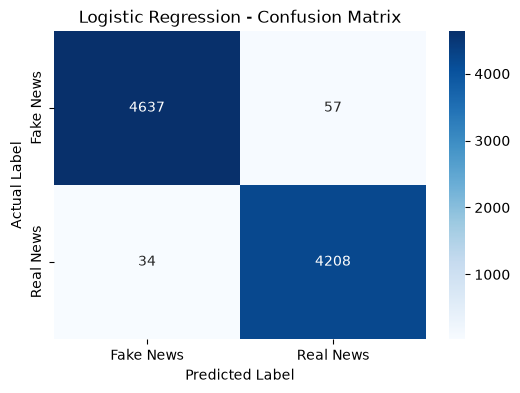

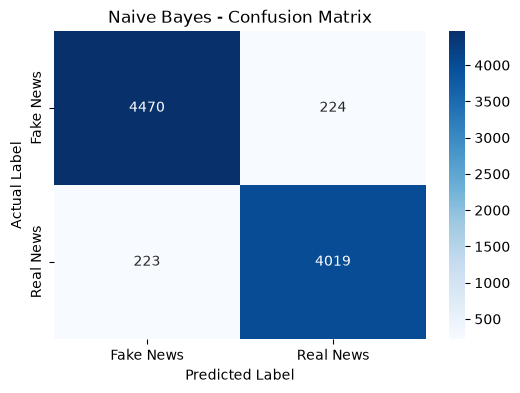

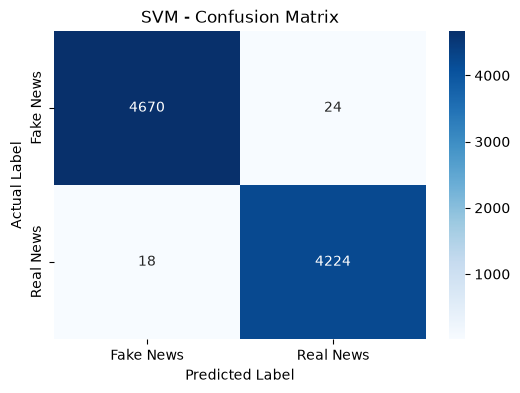

In [31]:
# generating confusion matrices
for name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions)
    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Fake News", "Real News"],
        yticklabels=["Fake News", "Real News"]
    )
    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    plt.show()

In [32]:
results_df.to_csv("../dataset/model_comparison.csv", index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [33]:
import joblib

# saving the best classification model
joblib.dump(svm_model, "../models/fake_news_svm.pkl")

# saving the TF-IDF vectorizer
joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

print("Best model saved successfully!")

Best model saved successfully!


In [34]:
# preparing data for clustering

cluster_data = df["content"].copy()

print("Total articles:", len(cluster_data))

print("\nFirst 5 articles:")
display(cluster_data.head())

Total articles: 44680

First 5 articles:


0    ben stein call th circuit court commit coup ta...
1    trump drop steve bannon nation secur council w...
2    puerto rico expect u lift jone act ship restri...
3    oop trump accident confirm leak isra intellig ...
4    donald trump head scotland reopen golf resort ...
Name: content, dtype: str

In [35]:
# converting news articles into tf-idf features
from sklearn.feature_extraction.text import TfidfVectorizer

cluster_tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=5, max_df=0.90)
X_cluster = cluster_tfidf.fit_transform(cluster_data)

print("Clustering TF-IDF Shape:", X_cluster.shape)

Clustering TF-IDF Shape: (44680, 5000)


K = 2 | Inertia = 42365.103570565436
K = 3 | Inertia = 42169.92262319805
K = 4 | Inertia = 42057.88461051509
K = 5 | Inertia = 41777.90221385829
K = 6 | Inertia = 41669.11967533083
K = 7 | Inertia = 41548.09347294195
K = 8 | Inertia = 41310.42650542887
K = 9 | Inertia = 41137.582228380896
K = 10 | Inertia = 40952.29512049951


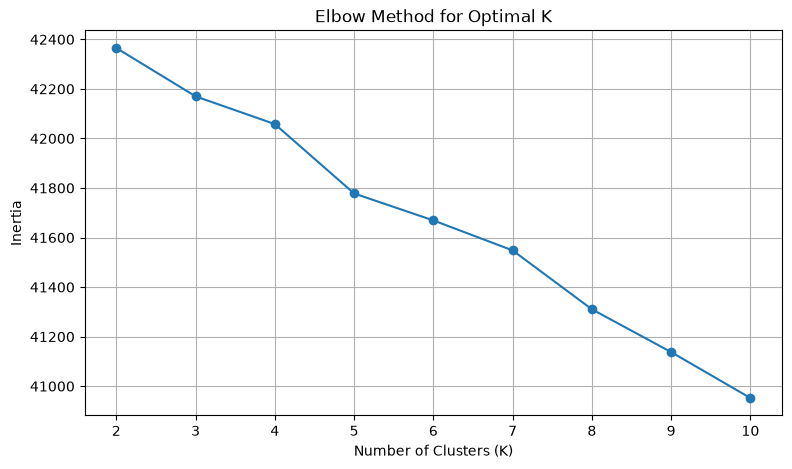

In [36]:
from sklearn.cluster import MiniBatchKMeans
import matplotlib.pyplot as plt

inertia_values = []
K_range = range(2, 11)

# calculating inertia for different k values
for k in K_range:
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=1024,
        n_init=3,
        max_iter=100
    )
    model.fit(X_cluster)
    inertia_values.append(model.inertia_)
    print("K =", k, "| Inertia =", model.inertia_)

# plotting the elbow graph
plt.figure(figsize=(9, 5))
plt.plot(list(K_range), inertia_values, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.xticks(list(K_range))
plt.grid(True)

plt.show()

K = 2 | Silhouette Score = 0.0144
K = 3 | Silhouette Score = 0.0145
K = 4 | Silhouette Score = 0.0158
K = 5 | Silhouette Score = 0.0151
K = 6 | Silhouette Score = 0.0136
K = 7 | Silhouette Score = 0.0146
K = 8 | Silhouette Score = 0.0192
K = 9 | Silhouette Score = 0.0217
K = 10 | Silhouette Score = 0.0233


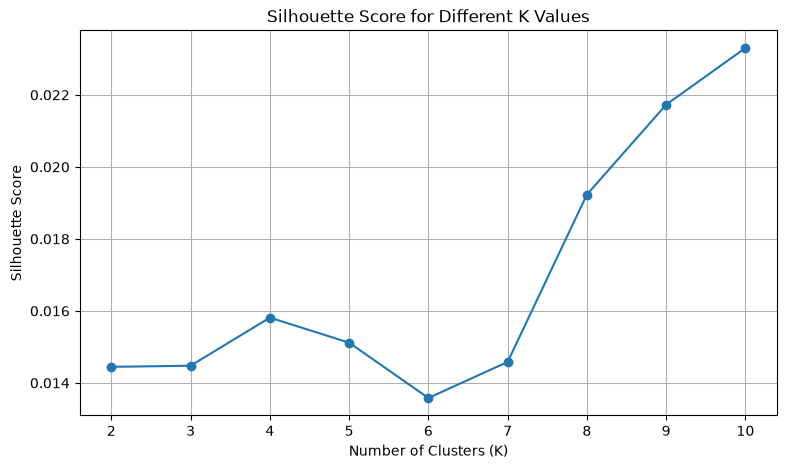

In [37]:
# calculating silhouette score
from sklearn.metrics import silhouette_score

silhouette_values = []
for k in K_range:
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=1024,
        n_init=3,
        max_iter=100
    )
    cluster_labels = model.fit_predict(X_cluster)
    score = silhouette_score(
        X_cluster,
        cluster_labels,
        metric="cosine",
        sample_size=3000,
        random_state=42
    )
    silhouette_values.append(score)

    print("K =", k, "| Silhouette Score =", round(score, 4))

# visualizing silhouette score
plt.figure(figsize=(9, 5))
plt.plot(list(K_range), silhouette_values, marker="o")
plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.xticks(list(K_range))
plt.grid(True)

plt.show()

In [38]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

for k in range(11, 16):
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=1024,
        n_init=3,
        max_iter=100
    )
    labels = model.fit_predict(X_cluster)
    score = silhouette_score(
        X_cluster,
        labels,
        sample_size=3000,
        random_state=42,
        metric="cosine"
    )
    print(f"K = {k} | Silhouette Score = {score:.4f}")

K = 11 | Silhouette Score = 0.0216
K = 12 | Silhouette Score = 0.0235
K = 13 | Silhouette Score = 0.0211
K = 14 | Silhouette Score = 0.0263
K = 15 | Silhouette Score = 0.0248


In [39]:
from sklearn.cluster import MiniBatchKMeans

# training the model
kmeans_model = MiniBatchKMeans(
    n_clusters=14,
    random_state=42,
    batch_size=1024,
    n_init=10,
    max_iter=200
)
kmeans_model.fit(X_cluster)
print("K-Means clustering completed successfully!")

# assigning clusters to articles
cluster_labels = kmeans_model.labels_
df["cluster"] = cluster_labels
print(df[["content", "cluster"]].head())

K-Means clustering completed successfully!
                                             content  cluster
0  ben stein call th circuit court commit coup ta...       13
1  trump drop steve bannon nation secur council w...        2
2  puerto rico expect u lift jone act ship restri...        7
3  oop trump accident confirm leak isra intellig ...        2
4  donald trump head scotland reopen golf resort ...        3


Number of articles in each cluster:
cluster
0      1487
1      2854
2      2571
3      7235
4       822
5      1245
6      3300
7     10809
8      1061
9       633
10     7387
11     1746
12     1858
13     1672
Name: count, dtype: int64


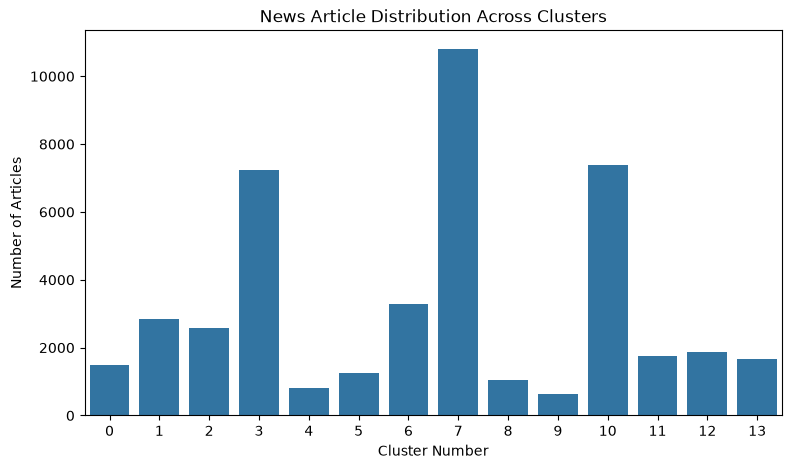

In [40]:
cluster_counts = df["cluster"].value_counts().sort_index()
print("Number of articles in each cluster:")
print(cluster_counts)

plt.figure(figsize=(9, 5))
sns.barplot(x=cluster_counts.index, y=cluster_counts.values)

plt.title("News Article Distribution Across Clusters")
plt.xlabel("Cluster Number")
plt.ylabel("Number of Articles")

plt.show()

In [41]:
# extracting feature names
feature_names = cluster_tfidf.get_feature_names_out()

# finding top 15 words in each cluster
order_centroids = kmeans_model.cluster_centers_.argsort()[:, ::-1]
for i in range(13):
    print("\nCLUSTER", i)
    top_words = [
        feature_names[ind]
        for ind in order_centroids[i, :15]
    ]
    print(", ".join(top_words))

for i in range(8):
    print("\n" + "=" * 60)
    print("CLUSTER", i)
    print("=" * 60)

    samples = df[df["cluster"] == i]["content"].head(3)
    for j, article in enumerate(samples, 1):
        print(f"\nArticle {j}:")
        print(article[:500])


CLUSTER 0
twitter, pic, twitter com, pic twitter, com, trump, realdonaldtrump, video, protest, tweet, januari, presid, march, cnn, hillari

CLUSTER 1
clinton, hillari, hillari clinton, email, trump, campaign, sander, democrat, state, said, fbi, video, presidenti, bill, elect

CLUSTER 2
russia, trump, russian, intellig, comey, investig, putin, said, fbi, elect, flynn, presid, committe, hous, moscow

CLUSTER 3
trump, donald, donald trump, republican, presid, said, campaign, elect, imag, support, peopl, white, like, would, say

CLUSTER 4
merkel, climat, germani, german, climat chang, coalit, parti, spd, berlin, said, chancellor, chang, afd, angela merkel, angela

CLUSTER 5
korea, north, north korea, china, korean, nuclear, missil, south, said, north korean, trump, south korea, pyongyang, test, japan

CLUSTER 6
senat, tax, republican, bill, hous, said, trump, democrat, would, legisl, vote, obamacar, healthcar, budget, plan

CLUSTER 7
video, peopl, said, trump, black, one, gun, like, state

Reduced data shape: (44680, 2)


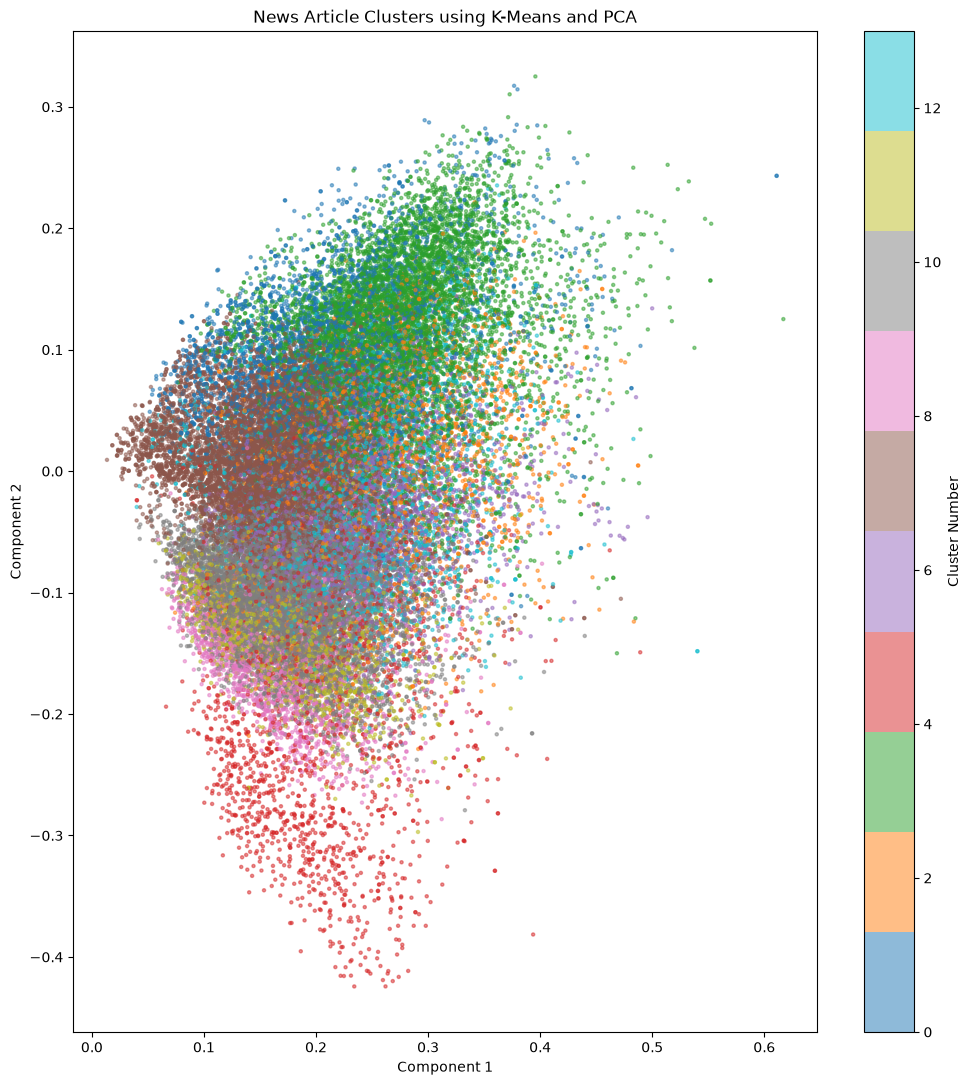

In [42]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=2, random_state=42)
X_reduced = svd.fit_transform(X_cluster)

print("Reduced data shape:", X_reduced.shape)

plt.figure(figsize=(12, 13))
plt.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    c=cluster_labels,
    cmap="tab10",
    s=5,
    alpha=0.5
)

plt.title("News Article Clusters using K-Means and PCA")
plt.xlabel("Component 1")
plt.ylabel("Component 2")

plt.colorbar(label="Cluster Number")

plt.show()

In [50]:
import pandas as pd
import os

# Generate 2D coordinates using the saved SVD model
cluster_coordinates = svd.transform(X_cluster)

# Verify that all arrays have matching lengths
assert len(df) == len(cluster_labels), "Dataset and cluster labels do not match!"
assert len(df) == len(cluster_coordinates), "Dataset and SVD coordinates do not match!"

# Create results dataframe
cluster_results = pd.DataFrame({
    "article": df["content"].astype(str).values,
    "x": cluster_coordinates[:, 0],
    "y": cluster_coordinates[:, 1],
    "cluster": cluster_labels
})

# Include the original class label if available
if "label" in df.columns:
    cluster_results["label"] = df["label"].values

# Save results
output_path = "../dataset/news_clustering_results.csv"

cluster_results.to_csv(output_path, index=False)

print("Clustering results saved successfully!")
print("Total articles:", len(cluster_results))
print("Total clusters:", cluster_results["cluster"].nunique())
print("\nSaved columns:")
print(cluster_results.columns.tolist())

print("\nSample records:")
display(cluster_results.head(3))


Clustering results saved successfully!
Total articles: 44680
Total clusters: 14

Saved columns:
['article', 'x', 'y', 'cluster', 'label']

Sample records:


,article,x,y,cluster,label
0,ben stein call th circuit court commit coup ta...,0.158906,0.018813,13,0
1,trump drop steve bannon nation secur council w...,0.324708,-0.080124,2,1
2,puerto rico expect u lift jone act ship restri...,0.141135,-0.056043,7,1


In [43]:
import joblib

joblib.dump(kmeans_model, "../models/news_clustering_model.pkl")
joblib.dump(cluster_tfidf, "../models/clustering_tfidf.pkl")
joblib.dump(svd, "../models/clustering_svd.pkl")

print("Clustering models saved successfully!")

Clustering models saved successfully!
